# Кластерный анализ методом DBSCAN

---

**Выполнил:** Романов Данил Павлович

**Группа:** М4181

---

### Импорты библиотек

In [79]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, fcluster

from sklearn.metrics import silhouette_score, adjusted_rand_score

### Загрузка и предобработка

Загрузим датасет **Economics of Cities** и предобработаем данные:
* **Загрузим данные с датасета**
* **Удалим строки с некорректными значениями**
* **Стандартизируем данные**

Подробнее проведена предобработка в [первой домашней работе](../HW1/lab1.ipynb), здесь упростим этот блок, чтобы не повторять одно и то же.

In [80]:
# Загрузка датасета
df = pd.read_csv(
    "../HW1/Задачи для лабораторной 1-3/задача_2_Economics of Cities/Econom_Cities_data.csv",
    sep=";",
    decimal=",",
)

# Удаляем строки с некорректными значениями
df = df[(df != -9999).all(axis=1)].reset_index(drop=True)

# Стандартизируем данные
scaler = StandardScaler()
scaled = scaler.fit_transform(df[df.columns[1:]])
df_scaled = pd.DataFrame(scaled, columns=df.columns[1:])

# Посмотрим на данные после предобработки
df_scaled.describe()

,Work,Price,Salary
count,4.600000e+01,4.600000e+01,4.600000e+01
mean,6.365681e-16,-4.247810e-16,1.061952e-16
std,1.011050e+00,1.011050e+00,1.011050e+00
min,-1.721863e+00,-1.881316e+00,-1.504695e+00
25%,-7.809400e-01,-8.662088e-01,-1.027914e+00
50%,-1.792714e-01,4.017885e-02,1.676125e-01
75%,5.586788e-01,5.577770e-01,8.230592e-01
max,2.871116e+00,2.146023e+00,2.468822e+00


### Описание метода DBSCAN

**DBSCAN (Density-Based Spatial Clustering of Applications with Noise)** — алгоритм кластеризации, основанный на плотности расположения объектов. Он объединяет объекты, находящиеся в областях высокой плотности, и позволяет выделять шумовые наблюдения.

Для работы алгоритма используются два основных параметра:

- `eps` — радиус окрестности точки, определяющий максимальное расстояние до соседних объектов.
- `min_samples` — минимальное количество объектов в окрестности, необходимое для того, чтобы точка считалась ядровой. Сама точка также учитывается.

#### Математическое описание

**1. Метрика расстояния**

Для определения близости объектов используется некоторая метрика расстояния $d(x_i, x_j)$. Выбор конкретной метрики зависит от данных и настроек алгоритма.

Одним из наиболее распространённых вариантов является евклидово расстояние:

$$
d(x_i, x_j) = \sqrt{\sum_{k=1}^{m}(x_{ik}-x_{jk})^2}
$$

**2. ε-окрестность**

ε-окрестностью точки $x_i$ называется множество объектов, расстояние до которых не превышает заданного радиуса $\varepsilon$:

$$
N_{\varepsilon}(x_i) =
\{x_j \in X \mid d(x_i,x_j) \leq \varepsilon\}
$$

**3. Условие ядровой точки**

Точка считается ядровой, если количество объектов в её ε-окрестности не меньше заданного значения $MinPts$:

$$
|N_{\varepsilon}(x_i)| \geq MinPts
$$

**4. Типы точек**

В зависимости от плотности расположения выделяют три типа объектов:

- **Ядровые точки (Core points)** — имеют достаточное количество соседей в пределах радиуса $\varepsilon$.
- **Граничные точки (Border points)** — находятся в окрестности ядровых точек, но сами не удовлетворяют условию ядровой точки.
- **Шумовые точки (Noise points)** — не относятся ни к одному кластеру и не находятся в окрестности ядровых точек.

**5. Плотностная достижимость**

Точка $x_j$ непосредственно достижима по плотности из точки $x_i$, если она находится в её ε-окрестности, а $x_i$ является ядровой точкой:

$$
x_j \in N_{\varepsilon}(x_i)
\quad \land \quad
|N_{\varepsilon}(x_i)| \geq MinPts
$$

Последовательность таких связей позволяет объединять объекты в кластеры.

#### Особенности алгоритма

В отличие от K-means, DBSCAN:
- Не требует заранее задавать количество кластеров.
- Может обнаруживать кластеры произвольной формы.
- Позволяет выделять шумовые объекты.
- Чувствителен к выбору параметров `eps` и `min_samples`.

#### Алгоритм метода DBSCAN

Алгоритм проходит по всем точкам и выполняет следующие действия:

1. **Выбирает точку**. Проверяет её ε-окрестность — ищет все объекты, находящиеся на расстоянии не больше eps.
2. **Проверяет плотность**. Если количество соседей меньше min_samples, точка пока считается потенциальным шумом. Если соседей достаточно — точка становится ядровой.
3. **Формирует кластер**. От ядровой точки алгоритм начинает добавлять соседние точки в кластер. Если среди соседей есть другие ядровые точки, алгоритм также исследует их окрестности и расширяет кластер.
4. **Добавляет граничные точки**. Точки, которые сами не являются ядровыми, но находятся рядом с ядровыми, присоединяются к соответствующему кластеру.
5. **Выделяет шум**. Точки, которые не удалось присоединить ни к одному кластеру, остаются шумовыми.
6. **Повторяет процесс**. Алгоритм продолжает работу, пока не обработает все точки.

DBSCAN начинает с плотных областей и постепенно расширяет их за счёт соседних объектов. Поэтому ему не нужно заранее знать количество кластеров.

### Подбор параметров

Переберём несколько значений параметра `min_samples` и посмотрим на то, как они влияют на расстояния до ближайших соседей. Выбор параметра осуществляется по формуле:

$$ min\_samples \ge d+1,$$

где $d$ - размерность пространства признаков. Т.е. минимальное значение `min_samples` можно выбирать не меньше количества признаков плюс один. Так как у нас три признака (`Price`, `Salary`, `Work`) **возьмем диапазон $[4, 6]$.**

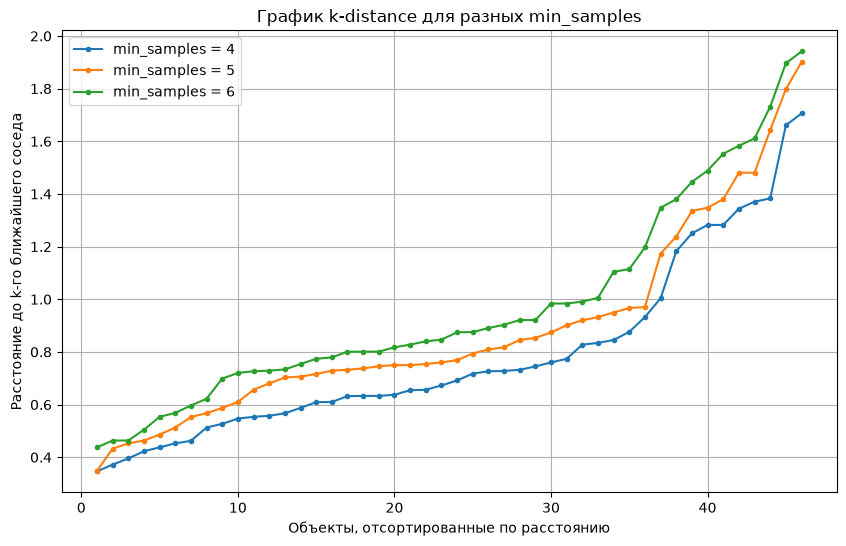

In [81]:
min_samples_values = [4, 5, 6]

plt.figure(figsize=(10, 6))

for min_samples in min_samples_values:
    # обучение модели NearestNeighbors для поиска k ближайших соседей
    neighbors = NearestNeighbors(n_neighbors=min_samples)
    neighbors.fit(df_scaled)

    # вычисление расстояний до k ближайших соседей для каждого объекта
    distances, indices = neighbors.kneighbors(df_scaled)
    k_distances = np.sort(distances[:, -1])

    # построение графика k-distance
    plt.plot(
        range(1, len(k_distances) + 1),
        k_distances,
        marker=".",
        label=f"min_samples = {min_samples}",
    )

plt.title("График k-distance для разных min_samples")
plt.xlabel("Объекты, отсортированные по расстоянию")
plt.ylabel("Расстояние до k-го ближайшего соседа")
plt.legend()
plt.grid()
plt.show()

Для подбора параметра `eps` используется график k-distance, на нём отображаются расстояния от каждой точки до её k-го ближайшего соседа.

По графику видно, что на всех трех кривых есть заметный переход к резкому росту расстояний в правой части графика. На эту область стоит опираться при выборе параметра `eps`.

| `min_samples` | Примерная область `eps` |
|---:|---:|
| 4 | 0.9 - 1.0 |
| 5 | 1.0 - 1.2 |
| 6 | 1.2 - 1.4 |

На графике нет однозначного "локтя", поэтому окончательный выбор будем делать по результатам кластеризации.

Возьмем диапазон $[0.9, 1.4]$ и найдем отпимальное значение параметра `eps`

In [82]:
eps_values = np.arange(0.9, 1.5, 0.1)
min_samples_values = [4, 5, 6]

results = []

for min_samples in min_samples_values:
    for eps in eps_values:
        # обучение модели DBSCAN с текущими параметрами eps и min_samples
        dbscan = DBSCAN(eps=round(eps, 2), min_samples=min_samples)

        # применение модели к данным
        labels = dbscan.fit_predict(df_scaled)

        # подсчет количества кластеров и шумовых объектов
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = np.sum(labels == -1)

        # Silhouette рассчитываем без шумовых объектов
        mask = labels != -1
        labels_without_noise = labels[mask]
        X_without_noise = df_scaled.loc[mask]

        # проверяем, что количество кластеров больше или равно 2 и меньше количества объектов без шума
        if 2 <= len(set(labels_without_noise)) < len(labels_without_noise):
            silhouette = silhouette_score(X_without_noise, labels_without_noise)
        else:
            silhouette = np.nan

        # сохраняем результаты для текущих параметров eps и min_samples
        results.append(
            {
                "eps": round(eps, 2),
                "min_samples": min_samples,
                "clusters": n_clusters,
                "noise": n_noise,
                "noise_percent": round(n_noise / len(df_scaled) * 100, 2),
                "silhouette": silhouette,
            }
        )

dbscan_results = pd.DataFrame(results)
dbscan_results.round(3)

,eps,min_samples,clusters,noise,noise_percent,silhouette
0,0.9,4,1,8,17.39,NaN
1,1.0,4,1,8,17.39,NaN
2,1.1,4,1,7,15.22,NaN
3,1.2,4,1,4,8.70,NaN
4,1.3,4,1,1,2.17,NaN
5,1.4,4,1,1,2.17,NaN
6,0.9,5,2,8,17.39,0.512
7,1.0,5,1,8,17.39,NaN
8,1.1,5,1,7,15.22,NaN
9,1.2,5,1,5,10.87,NaN


Только для двух вариантов алгоритм **смог найти хотя бы два кластера**:

| `eps` | `min_samples` | Кластеров | Шумовых точек | Доля шума | Silhouette |
|---:|---:|---:|---:|---:|---:|
| 0.9 | 5 | 2 | 8 | 17.39% | 0.512 |
| 0.9 | 6 | 2 | 9 | 19.57% | 0.518 |

Во всех остальных комбинациях алгоритм сформировал один кластер, а остальные точки отнёс к шуму либо объединил в одну группу. В обоих случаях `eps` равен $0.9$, но в первом случае количество шумовых точек меньше, однако силуэт, незначительно, но меньше. 

Прежде чем возьмем один из этих вариантов, посмотрим, не дают ли значения `eps` в диапазоне $[0.5, 0.9]$ лучших результатов

In [83]:
eps_values = np.arange(0.5, 0.95, 0.05)
min_samples_values = [4, 5, 6]

results = []

for min_samples in min_samples_values:
    for eps in eps_values:
        # обучение модели DBSCAN с текущими параметрами eps и min_samples
        dbscan = DBSCAN(eps=round(eps, 2), min_samples=min_samples)

        # применение модели к данным
        labels = dbscan.fit_predict(df_scaled)

        # подсчет количества кластеров и шумовых объектов
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = np.sum(labels == -1)

        # Silhouette рассчитываем без шумовых объектов
        mask = labels != -1
        labels_without_noise = labels[mask]
        X_without_noise = df_scaled.loc[mask]

        # проверяем, что количество кластеров больше или равно 2 и меньше количества объектов без шума
        if 2 <= len(set(labels_without_noise)) < len(labels_without_noise):
            silhouette = silhouette_score(X_without_noise, labels_without_noise)
        else:
            silhouette = np.nan

        # сохраняем результаты для текущих параметров eps и min_samples
        results.append(
            {
                "eps": round(eps, 2),
                "min_samples": min_samples,
                "clusters": n_clusters,
                "noise": n_noise,
                "noise_percent": round(n_noise / len(df_scaled) * 100, 2),
                "silhouette": silhouette,
            }
        )

dbscan_results = pd.DataFrame(results)
dbscan_results.round(3)

,eps,min_samples,clusters,noise,noise_percent,silhouette
0,0.50,4,1,35,76.09,NaN
1,0.55,4,2,30,65.22,0.724
2,0.60,4,3,21,45.65,0.477
3,0.65,4,3,15,32.61,0.379
4,0.70,4,3,11,23.91,0.356
5,0.75,4,2,9,19.57,0.523
6,0.80,4,2,8,17.39,0.512
7,0.85,4,1,8,17.39,NaN
8,0.90,4,1,8,17.39,NaN
9,0.50,5,1,36,78.26,NaN


Самое высокое значение силуэта получилось $0.726$ (при `eps` = $0.60$ и `min_samples` = $5$), но процент шума довольно большой ($\approx 60$%), посмотрим на варианты с более-менее адекватными значениями процента шума

In [84]:
valid_results = dbscan_results[
    (dbscan_results["clusters"] >= 2) & (dbscan_results["noise_percent"] < 30)
]

valid_results.sort_values(
    ["silhouette", "noise_percent"], ascending=[False, True]
).round(3)

,eps,min_samples,clusters,noise,noise_percent,silhouette
24,0.80,6,2,12,26.09,0.539
25,0.85,6,2,11,23.91,0.529
5,0.75,4,2,9,19.57,0.523
14,0.75,5,2,9,19.57,0.523
15,0.80,5,2,9,19.57,0.523
16,0.85,5,2,9,19.57,0.523
26,0.90,6,2,9,19.57,0.518
6,0.80,4,2,8,17.39,0.512
17,0.90,5,2,8,17.39,0.512
4,0.70,4,3,11,23.91,0.356


Тут также есть неплохие варианты, которые можно было бы рассмотреть, но остановимся пока на значениях, что нашли в первый раз:
$$eps = 0.9 \text{ и } min\_samples = 5$$

Так алгоритм выделяет **два кластера**, шумовыми остаются $8$ городов из $46$ и силуэт равен $0.512$.

### Кластеризация

Обучим итоговую модель

In [85]:
best_eps = 0.9
best_min_samples = 5

# Обучение модели DBSCAN с лучшими параметрами
dbscan = DBSCAN(eps=best_eps, min_samples=best_min_samples)
df["dbscan_cluster"] = dbscan.fit_predict(df_scaled)

n_clusters = len(set(df["dbscan_cluster"])) - 1  # минус шумовой кластер -1
n_noise = (df["dbscan_cluster"] == -1).sum()

# Вывод результатов
dbscan_summary = pd.DataFrame(
    {
        "Показатель": [
            "Количество кластеров",
            "Количество городов",
            "Количество шумовых объектов",
            "Доля шумовых объектов",
        ],
        "Значение": [n_clusters, len(df), n_noise, f"{n_noise / len(df) * 100:.2f}%"],
    }
)

dbscan_summary

,Показатель,Значение
0,Количество кластеров,2
1,Количество городов,46
2,Количество шумовых объектов,8
3,Доля шумовых объектов,17.39%


In [86]:
cluster_sizes = (
    df["dbscan_cluster"]
    .value_counts()
    .rename_axis("Кластер")
    .reset_index(name="Количество городов")
)
cluster_sizes

,Кластер,Количество городов
0,0,19
1,1,19
2,-1,8


Таким образом у нас вышло два кластера с 19-ю городами в каждом и шумовой кластер (-1) с 8-ю городами. Выведем города в каждом кластере:

In [87]:
for cluster_id, group in df.groupby("dbscan_cluster"):
    if cluster_id == -1:
        print(f"\nШумовые объекты ({len(group)} городов):")
    else:
        print(f"\nКластер {cluster_id} ({len(group)} городов):")

    print(", ".join(group["City"].tolist()))


Шумовые объекты (8 городов):
Geneva, Helsinki, Hong_Kong, Oslo, Stockholm, Taipei, Tokyo, Zurich

Кластер 0 (19 городов):
Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Houston, London, Los_Angeles, Luxembourg, Madrid, Milan, Montreal, New_York, Paris, Sydney, Toronto, Vienna

Кластер 1 (19 городов):
Athens, Bogota, Bombay, Buenos_Aires, Caracas, Johannesburg, Kuala_Lumpur, Lagos, Lisbon, Manila, Mexico_City, Nairobi, Nicosia, Panama, Rio_de_Janeiro, San_Paulo, Seoul, Singpore, Tel_Aviv


Теперь посмотрим на средние значения признаков в кластерах

In [88]:
df.groupby("dbscan_cluster")[["Work", "Price", "Salary"]].mean().round(2)

,Work,Price,Salary
dbscan_cluster,,,
-1,1900.38,99.92,61.26
0,1792.00,77.53,55.16
1,1959.21,50.12,14.79


**Какие выводы можно сделать:**

**Кластер 0**: города с относительно высокими ценами и зарплатами. В него попали Amsterdam, Brussels, Copenhagen, London, Luxembourg, New York, Paris, Sydney, Toronto и другие города.

Средние показатели:

- `Work` - **1792**;
- `Price` - **77.53**;
- `Salary` - **55.16**.

**Кластер 1**: города с более низкими ценами и зарплатами. Среди них Athens, Bogota, Bombay, Buenos Aires, Lagos, Manila, Mexico City, Nairobi, Rio de Janeiro и другие.

Средние показатели:

- `Work` - **1959.21**;
- `Price` - **50.12**;
- `Salary` - **14.79**.

**Шумовые объекты**: города с особенно высокими значениями цен и зарплат. В эту группу попали Geneva, Helsinki, Hong Kong, Oslo, Stockholm, Taipei, Tokyo и Zurich.

Средние показатели:
`Work` - **1900.38**;
`Price` - **99.92**;
`Salary` - **61.26**.

DBSCAN не выделил шумовые города в отдельный кластер, а отметил как шум, это значит, что они не образуют достаточно плотных групп при выбранных параметрах.

### Визуализация результатов

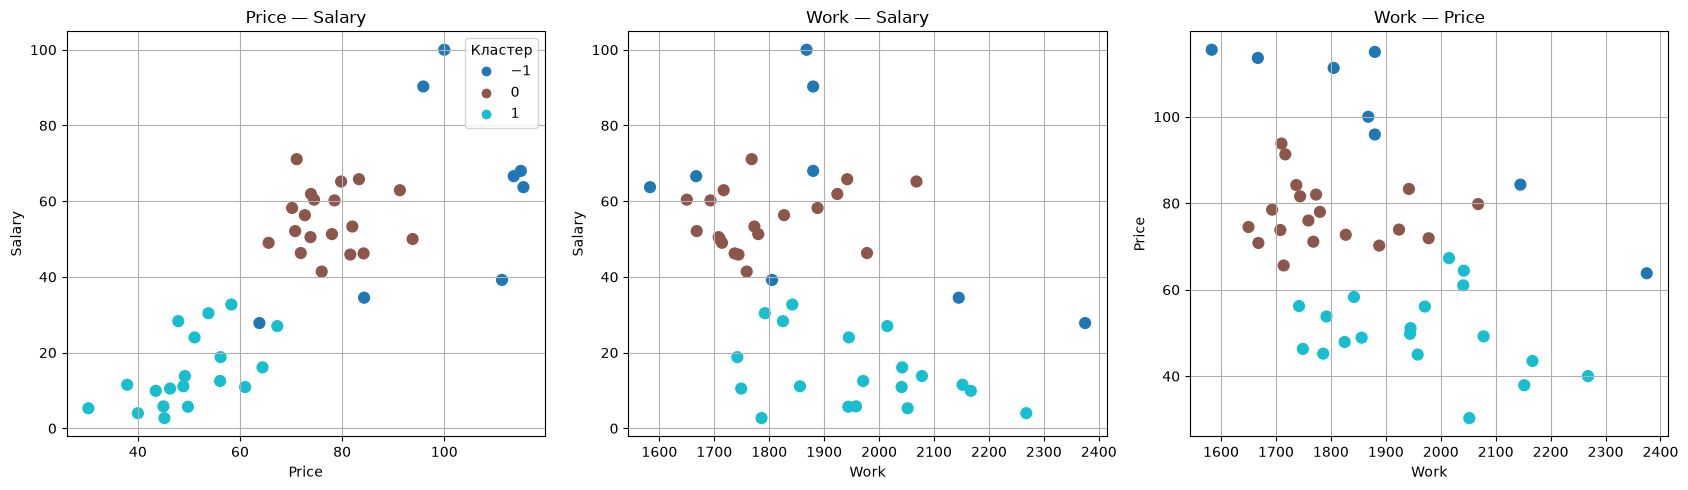

In [89]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

features = [("Price", "Salary"), ("Work", "Salary"), ("Work", "Price")]

for ax, (x, y) in zip(axes, features):
    scatter = ax.scatter(df[x], df[y], c=df["dbscan_cluster"], cmap="tab10", s=60)

    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(f"{x} — {y}")
    ax.grid()

axes[0].legend(*scatter.legend_elements(), title="Кластер")

plt.tight_layout()
plt.show()

На графиках видно распределение городов по найденным группам. Шумовые объекты отображаются отдельным цветом.

### Сравнение с предыдущими методами

In [90]:
# K-means
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_kmeans = kmeans.fit_predict(df_scaled)

# Иерархическая кластеризация (метод Уорда)
link = linkage(df_scaled, method="ward", metric="euclidean")

labels_ward = fcluster(link, t=3, criterion="maxclust")

# Сохраняем результаты
df["kmeans_cluster"] = labels_kmeans
df["ward_cluster"] = labels_ward

# Сравниваем результаты трёх алгоритмов по ARI
ari_comparison = pd.DataFrame(
    {
        "Сравниваемые алгоритмы": [
            "K-means и DBSCAN",
            "Ward и DBSCAN",
            "K-means и Ward",
        ],
        "ARI": [
            adjusted_rand_score(labels_kmeans, df["dbscan_cluster"]),
            adjusted_rand_score(labels_ward, df["dbscan_cluster"]),
            adjusted_rand_score(labels_kmeans, labels_ward),
        ],
    }
)

ari_comparison.round(3)

,Сравниваемые алгоритмы,ARI
0,K-means и DBSCAN,0.525
1,Ward и DBSCAN,0.520
2,K-means и Ward,0.862


Сравнение результатов трёх алгоритмов по метрике Adjusted Rand Index показало, что наиболее близкие результаты получили K-means и иерархическая кластеризация методом Уорда (ARI = 0.862). Это свидетельствует о значительном сходстве сформированных ими групп городов.

Сходство DBSCAN с K-means (ARI = 0.525) и методом Уорда (ARI = 0.520) оказалось заметно ниже. Это объясняется различиями в принципах работы алгоритмов: K-means и Ward формируют заданное количество кластеров, тогда как DBSCAN выделяет плотные области и отдельно определяет шумовые объекты.

Таким образом, K-means и иерархическая кластеризация продемонстрировали наиболее согласованное разбиение данных. DBSCAN выявил другую структуру групп, в том числе выделив 8 городов как шумовые объекты.

## Общий вывод

В ходе лабораторной работы был проведён кластерный анализ экономических показателей городов с использованием алгоритма **DBSCAN**. Для исследования использовался набор данных из 46 городов с тремя признаками: Work, Price и Salary.

### 1. Подготовка данных

На этапе предобработки были исключены два города - Cairo и Jakarta, поскольку в их данных присутствовали пропущенные значения, обозначенные числом `-9999`. После очистки осталось 46 наблюдений.

Для корректной работы алгоритмов признаки были стандартизированы с помощью `StandardScaler`, чтобы исключить влияние различий в масштабах измерений.

### 2. Выбор параметров DBSCAN

Для определения подходящих параметров алгоритма были построены графики k-distance для нескольких значений `min_samples`: 4, 5 и 6.

В дальнейшем было проведено сравнение различных комбинаций `eps` и `min_samples`. При выборе параметров учитывались количество сформированных кластеров, число шумовых объектов и значение коэффициента силуэта.

В качестве итоговой конфигурации были выбраны:

- `eps = 0.9`;
- `min_samples = 5`.

При этих параметрах алгоритм выделил два кластера и определил 8 шумовых объектов, что составляет 17.39% от общего количества городов. Значение коэффициента силуэта составило 0.512 (рассчитано без учёта шумовых объектов).

Выбранная конфигурация представляет собой компромисс между формированием нескольких кластеров и относительно небольшой долей шума среди проверенных комбинаций параметров.

### 3. Результаты кластеризации

DBSCAN разделил города на две группы по 19 объектов в каждой, а оставшиеся 8 городов отнёс к шумовым объектам.

Анализ средних значений признаков показал следующие различия:

- **Кластер 0:** Work — 1792.00, Price — 77.53, Salary — 55.16. Группа характеризуется более высокими значениями Price и Salary.
- **Кластер 1:** Work — 1959.21, Price — 50.12, Salary — 14.79. Для этой группы характерны более низкие значения Price и Salary, но более высокий показатель Work.
- **Шумовые объекты:** Work — 1900.38, Price — 99.92, Salary — 61.26. Эти города не были отнесены алгоритмом к плотным группам.

К шумовым объектам попали Geneva, Helsinki, Hong_Kong, Oslo, Stockholm, Taipei, Tokyo и Zurich. Их выделение в качестве шума не означает, что данные являются ошибочными: алгоритм лишь не обнаружил для них достаточно плотного окружения при выбранных параметрах.

### 4. Сравнение алгоритмов кластеризации

Для дополнительной оценки результатов DBSCAN было проведено сравнение с K-means и иерархической кластеризацией методом Уорда с помощью метрики Adjusted Rand Index (ARI).

Получены следующие значения:

- K-means и DBSCAN — **0.525**;
- Ward и DBSCAN — **0.520**;
- K-means и Ward — **0.862**.

Наибольшее сходство продемонстрировали K-means и иерархическая кластеризация. Результаты DBSCAN с двумя другими алгоритмами оказались менее похожими. Это связано с различиями в принципах работы методов: K-means и Ward формируют заданное количество групп, тогда как DBSCAN выделяет плотные области и определяет отдельные объекты как шум.

### Итог

В результате лабораторной работы был изучен алгоритм DBSCAN, исследовано влияние его параметров на структуру кластеров и выполнена интерпретация полученных групп городов.

Эксперимент показал, что DBSCAN позволяет выявлять плотные группы объектов и обнаруживать наблюдения, которые не относятся к этим группам. При этом результат существенно зависит от выбора `eps` и `min_samples`.

Сравнение с K-means и иерархической кластеризацией показало, что последние два метода дали более близкие результаты между собой (ARI = 0.862), тогда как DBSCAN сформировал отличающуюся структуру разбиения. Таким образом, использование нескольких алгоритмов позволяет рассмотреть структуру данных с разных сторон и получить более полное представление о сходстве экономических характеристик исследуемых городов.